In [7]:
# Initialize Otter
import otter
grader = otter.Notebook("week5.ipynb")

# HW5: Optimization
#### CS-31: Foundations for Artificial Intelligence
*Point breakdown: 50 autograded · 40 manually graded · 10 collaboration statement = 100*



*You are allowed to work in groups for the lab. You must write anything that will be turned in -- all code and all written solutions -- on your own. You must list all people and resources that you interacted with in the Collaboration Statement below. See [course policies](https://www.cs.tufts.edu/comp/31/policy.html) for more information.*

--

In this lab, you'll get some hands-on practice with optimization libraries! The first part will be using OR-Tools to solve a network flow logistics problem. The second part will be using [scipy](https://scipy.org/) - a library for scientific computing - to minimize continuous functions. You'll then use scipy to run least squares regression on sinusoidal data.

**AI / Source Disclosure**
- The basics of LP in OR-Tools are pulled from their [official documentation](https://developers.google.com/optimization/lp/lp_example).
- The basics of continuous optimization in scipy are also pulled from their [respective documentation](https://docs.scipy.org/doc/scipy/tutorial/optimize.html). 
- I used Claude to help generate the plotting code for the Rosenbrock function, as well as the plots for the temperature data.
- All other prose and code was written by me.

### **Table of Contents**

1) Coding: Linear Programming
2) Coding: Continuous Optimization
3) Collaboration Statement


## **1. Linear Programming**


### **1.1: Linear Programming in OR-Tools**

Linear programming in OR-Tools is a lot like constraint satisfaction! This info is pulled from [this tutorial](https://developers.google.com/optimization/lp/lp_example), so you should take a look.

In general, the recipe for solving an LP problem is:

1. Import the linear solver wrapper,
2. declare the LP solver,
3. define the variables,
4. define the constraints,
5. define the objective,
6. call the LP solver; and
7. display the solution


**Import the linear solver wrapper and declare the solver**

A "wrapper" is just some code that's used to call some other existing code. Google OR-Tools linear solver functions are a wrapper around their existing linear solver `GLOP` (Google Linear Optimization Package).

In [8]:
from ortools.linear_solver import pywraplp

solver = pywraplp.Solver.CreateSolver("GLOP")

**Create variables**

Much like in constraint satisfaction, we have to specially declare our variables that we want to optimize against.

Let's create variables x and y whose values are in the range from 0 to infinity. See how this implicitly encodes a non-negativity constraint?

In [9]:
x = solver.NumVar(0, solver.infinity(), "x")
y = solver.NumVar(0, solver.infinity(), "y")

print("Number of variables =", solver.NumVariables())

Number of variables = 2


**Define the constraints**

Next, let's define the constraints on the variables. Notice how it's pretty simple to define the constraints - we can just write out the inequalities we want.

In [10]:
# Constraint 0: x + 2y <= 14.
solver.Add(x + 2 * y <= 14.0)

# Constraint 1: 3x - y >= 0.
solver.Add(3 * x - y >= 0.0)

# Constraint 2: x - y <= 2.
solver.Add(x - y <= 2.0)

print("Number of constraints =", solver.NumConstraints())

Number of constraints = 3


**Define the objective function**

The following code defines the objective function, 3x + 4y, and specifies that this is a maximization problem.

In [11]:
# Objective function: 3x + 4y.
solver.Maximize(3 * x + 4 * y)

**Call the solver**

The following code invokes the solver.

In [12]:
print(f"Solving with {solver.SolverVersion()}")
status = solver.Solve()

Solving with Glop solver v9.15.6755


**Display the solution**

The following code displays the solution.

In [13]:
if status == pywraplp.Solver.OPTIMAL:
    print("Solution:")

    # Get the actual final maximized value
    print(f"Objective value = {solver.Objective().Value():0.1f}")

    # Get the solution value by calling .solution_value()
    print(f"x = {x.solution_value():0.1f}")
    print(f"y = {y.solution_value():0.1f}")
else:
    print("The problem does not have an optimal solution.")

Solution:
Objective value = 34.0
x = 6.0
y = 4.0


#### **Exercise 1.1: Solving a Flow Problem**

You are an analyst for *PlushLogic*, a company that provides logistics services to move plushies and plushie accessories from the people who have them to the markets that want them. Specifically, your niche is on distributing polyfill stuffing - used for the critical market sector of stuffed animals, cloud decorations, and comfy cushions. You're in a partnership with two 'distributors' of stuffing which handle the raw product - **Amadi's Plush Warehouse (A)** and **Bo's Stuffing Storage Solutions (B)**. You are also in a partnership with two craft stores (your markets) that want stuffing delivered to them - **Carmen's Crafts (C)** and **Daniel's Designs (D)**. You are working out how to most efficiently route the stuffing from the distributors to the markets for the month.

Each distributor (A and B) has a maximum amount of product (unit of stuffing) on hand that they can ship (`max_ship`). In addition, each distributor also has a *minimum* amount of product that they need to offload (`min_ship`), as they need to make room for next month's delivery of various other products.

Each market (D and C) has an associated gross profit for each unit of product sold that is passed along to us (`gross_profit_per_sale`). Each market also has a maximum amount of product they're willing to receive (`max_demand`). Finally, we have also existing contracts with each market, so we are required to ship a specified minimum amount of product to each market (`min_demand`).

In [14]:
distributors=[
    {"name": "A", "min_ship": 15, "max_ship": 30},
    {"name": "B", "min_ship": 20, "max_ship": 60}
]

markets=[
    {"name": "C", "min_demand": 10, "max_demand": 35, "gross_profit_per_sale": 12},
    {"name": "D", "min_demand": 25, "max_demand": 50, "gross_profit_per_sale": 8}
]

In our current distribution network, each route from distributor $i$ to market $j$ has an associated maximum capacity - which represents how many units of stuffing we can physically ship from $i$ to $j$ given our current resources. This is an abstraction of our fleet size and our distribution network. `cap[i][j]` represents the capacity of the network to ship from distributor $i$ to market $j$.

In [15]:
cap = [
    [10, 25], 
    [30, 40]
]

# Maximum capacity from shipping from A to C
print(cap[0][0])

10


Finally, each route $i$ to market $j$ has an associated *cost to ship per unit product*. `cost[i][j]` tells us how much it costs us to ship one unit of product from $i$ to $j$. If we were to ship *n* units on route $i \rightarrow j$, the total cost to ship those n units would be $n*cost[i][j]$.

In [16]:
cost = [
    [2, 10], 
    [6, 3]
]

# Cost of shipping one unit of product from B to C
print(cost[1][0])

6


Give the above constraints, **set up and then solve a linear program to find an assignment of flows on each edge such that net profit is maximized**. As a reminder, net profit is `gross_profit - costs`, so when you ship from distributor $i$ to market $j$, you will have to account for how much the product is sold for in $j$ minus the cost it took to ship the product from $i$. We recommend drawing out the flow problem as a graph (see optimization lecture slides), and annotating the nodes and edges in order to reason about the constraints you will need.

We started you off below with your variables, please operate on the variables stored in `flows`.

In [17]:
from ortools.linear_solver import pywraplp
flows = {}

s = pywraplp.Solver.CreateSolver("GLOP")

for i, distributor in enumerate(distributors):
    for j, market in enumerate(markets):
        # Our value for the flow along each i->j path ranges between [0, cap[i][j]]
        flows[(i, j)] = s.NumVar(0, cap[i][j], f"flow_{distributors[i]['name']}_to_{markets[j]['name']}")

print(flows)

{(0, 0): flow_A_to_C, (0, 1): flow_A_to_D, (1, 0): flow_B_to_C, (1, 1): flow_B_to_D}


In [36]:
# Total shipments must respect each distributor's limits.
for i, distributor in enumerate(distributors):
    shipped = s.Sum(flows[(i, j)] for j in range(len(markets)))
    s.Add(shipped >= distributor["min_ship"])
    s.Add(shipped <= distributor["max_ship"])

# Total deliveries must respect each market's limits.
for j, market in enumerate(markets):
    received = s.Sum(flows[(i, j)] for i in range(len(distributors)))
    s.Add(received >= market["min_demand"])
    s.Add(received <= market["max_demand"])

s.Maximize(s.Sum(
    (market["gross_profit_per_sale"] - cost[i][j]) * flows[(i, j)]
    for i, distributor in enumerate(distributors)
    for j, market in enumerate(markets)
))

In [37]:
status = s.Solve()
print(f"  profit = {s.Objective().Value():.2f}")

for (i, j), v in flows.items():
    print(f"  {v.name():8s} = {v.solution_value():6.1f}")

  profit = 415.00
  flow_A_to_C =   10.0
  flow_A_to_D =    5.0
  flow_B_to_C =   25.0
  flow_B_to_D =   35.0


In [38]:
grader.check("q_lp_flow")

q_lp_flow results: All test cases passed!

#### **Exercise 1.2 (Written): Interpreting the Results (10 pts)**

Congrats - you solved a linear programming flow problem! You now have the maximum profit that you could achieve given the constraints, as well as assignment of flows from each distributor to market that leads to that - but what does it *mean*?

Analyze the proposed solution your solver gave and interpret the results from a cost-saving and profit-making perspective (*Hint:* It might help to calculate how much each edge is contributing to the profit). If you could make a recommendation to change one of the constraints (e.g. increase capacity along a route, negotiate an existing contract, reduce costs along a route) to better maximize profit, what would you change? In addition, what might an unintended consequence of this change be? Back up your claims with another solve of the LP with the modified constraint.

Explain your reasoning and analysis with minimal jargon - as if you would to explain the situation to a non-technical coworker.

<!-- BEGIN QUESTION -->

The best plan ships 10 units from A to C, 5 from A to D, 25 from B to C, and 35 from B to D. After shipping costs, each unit on these routes earns 10, -2, 6, and 5 respectively. Their total contributions are 100, -10, 150, and 175, for a net profit of 415.
A to D loses money, but A must ship at least 15 units and can send only 10 to C. This forces at least 5 units onto the unprofitable route. B ships all 60 available units. C receives its maximum of 35 units, because B earns 6 per unit going to C compared with 5 going to D.
I would increase the A-to-C route capacity from 10 to 15 units. The new solve below ships 15, 0, 20, and 40 units on the same four routes, increasing profit to 470, a gain of 55. Moving five A units from D to C gains 60. Since C was already full, five B units must then move from C to D, reducing profit by 5; the net gain is 55.
An unintended consequence could be the cost of extra vehicles, staff, or storage needed for the expanded route. Those expansion costs are absent from this model; if they exceed 55 for the modeled month, the change would not improve actual profit. Increasing route capacity could also divert vehicles from other routes, which this model assumes remain unchanged. Both plans deliver 35 units to C and 40 to D.

<!-- END QUESTION -->



In [21]:
# Put any scratch code for your analysis here

## **2. Continuous Optimization**


### **2.1: Continuous Optimization in Numpy**

Switching gears, `scipy` is a library that provides a lot of useful functions for scientific computing. One of these is a set of gradient-based methods for optimizing continuous functions. Take a look at this [introduction](https://docs.scipy.org/doc/scipy/tutorial/optimize.html). 

In [22]:
import numpy as np
import matplotlib.pyplot as plt

To get familiar with minimizing, we'll first run scipy minimization on an instance of the [Rosenbrock function](https://en.wikipedia.org/wiki/Rosenbrock_function).

The Rosenbrock function in two dimensions is:

$f(x,y) = (a - x)^2 + b(y-x^2)^2$

for some values $a$ and $b$. You can verify via simple algebra that the function has a global minimum at $(x, y) = (a, a^2)$, where $f(x,y) = 0$. While it is easy to find the minimum algebraically (or even by calculus), the Rosenbrock function poses quite a challenge for numerical optimization algorithms. This is because:

> The global minimum is inside a long, narrow, parabolic-shaped flat valley. To find the valley is trivial. To converge to the global minimum, however, is difficult.

Let's define an instance of the Rosenbrock function with $a=1$ and $b=100$ (thus ensuring the global minimum is at $(1, 1)$).

One thing to note though: to work with the solver, our function has to accept our parameters as a single *list*. Instead of defining it as `rosenbrock(x, y)`, we define it as `rosenbrock(params)`, where `params[0] = x` and `params[1] = y`.

In [23]:
a = 1
b = 100

def rosenbrock(params):
    x = params[0]
    y = params[1]

    return (a - x)**2+b*(y-x**2)**2

Let's plot it.

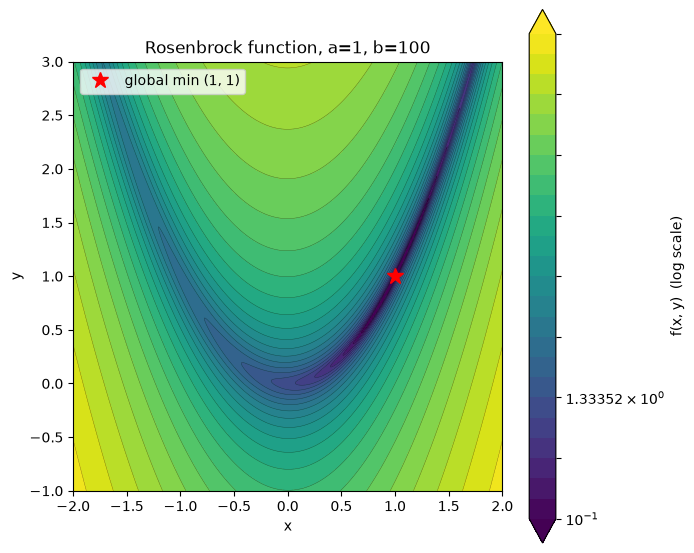

In [24]:
# Plot grid, you can ignore this code
from matplotlib.colors import LogNorm
x = np.linspace(-2, 2, 800)
y = np.linspace(-1, 3, 800)
X, Y = np.meshgrid(x, y)
Z = rosenbrock([X, Y])
 
# Plot countour lines
levels = np.logspace(-1, 3.5, 25)
fig, ax = plt.subplots(figsize=(7, 6))

# Plot heatmap
norm = LogNorm(vmin=levels[0], vmax=levels[-1])
cf = ax.contourf(X, Y, Z, levels=levels, norm=norm, cmap="viridis",
                 extend="both")

ax.contour(X, Y, Z, levels=levels, colors="k", linewidths=0.3, alpha=0.5)
fig.colorbar(cf, ax=ax, label="f(x, y)  (log scale)")
ax.plot(a, a ** 2, "r*", markersize=12, label=f"global min ({a}, {a**2})")
 
ax.set_xlim(-2, 2)
ax.set_ylim(-1, 3)
ax.set_aspect("equal")
ax.set_xlabel("x")
ax.set_ylabel("y")
ax.set_title(f"Rosenbrock function, a={a}, b={b}")
ax.legend(loc="upper left")
 
plt.tight_layout()


Now, let's try and find the minimum of this function numerically! We make an initial guess of where our minima might be, and then run our minimizer.

In [25]:
from scipy.optimize import minimize

# Let's say our initial guess is x = 2 and y = 3
initial_guess = [2,3]

res = minimize(rosenbrock, # The function we want to minimize
               initial_guess, # Our initial guess
               options = {'disp': True} # Display the solver results
               )


Optimization terminated successfully.
         Current function value: 0.000000
         Iterations: 22
         Function evaluations: 81
         Gradient evaluations: 27


We see that our solver ran without an issue. We went through 22 iterations of gradient descent.

Let's print our actual output. What we care about is the `res["x"]` value, which gives us the argument of the minimum.

In [26]:
print(res)

  message: Optimization terminated successfully.
  success: True
   status: 0
      fun: 2.035855055011918e-11
        x: [ 1.000e+00  1.000e+00]
      nit: 22
      jac: [ 5.616e-07 -3.142e-07]
 hess_inv: [[ 4.766e-01  9.520e-01]
            [ 9.520e-01  1.907e+00]]
     nfev: 81
     njev: 27


In [27]:
# Let's extract our values
argmin_x = res['x'][0]
argmin_y = res['x'][1]

print("Argmin X: ", argmin_x, "Argmin Y: ", argmin_y)

# We get pretty close to zero!
print("Value at argmin: ", rosenbrock([argmin_x, argmin_y]))

Argmin X:  0.9999954888569006 Argmin Y:  0.9999909687127954
Value at argmin:  2.035855055011918e-11


And that's how you minimize a function! Now the difficult part... what should we actually try and minimize?

One more tip before you move on: Numpy has a whole host of features, but a very useful one is [numpy arrays](https://numpy.org/doc/stable/reference/generated/numpy.array.html) of the same length can be operated on just like normal variables - they just apply the operations pairwise! This may make some of your calculations easier later.

In [28]:
X = np.array([1, 2, 3])
Y = np.array([2, 3, 4])

# [1**2, 2**2, 3**2]
squaring = X**2
print(squaring)

# [1+2, 2+3, 4+3]
summing = X+Y
print(summing)

# Some other operations
print(X*Y)
print(X-Y)
print(X+3)
print(3*X+Y)

[1 4 9]
[3 5 7]
[ 2  6 12]
[-1 -1 -1]
[4 5 6]
[ 5  9 13]


#### **Exercise 2.1: Fitting Temperature Data**


In this exercise, we're going to look at data from a weather station at the Boston-Logan airport from the last 10 years. We want to find some sort of function that we can learn the mean daily temperature from the data to help us predict future values.

Below is some simple code for loading data from a .CSV (`boston_logan_tmean_last10y.csv`) file using the `pandas` library. `pandas` is just a library that makes it really easy to load in and navigate tables of data. You don't need to worry about how to use `pandas` (for now). We load, and then plot the data.

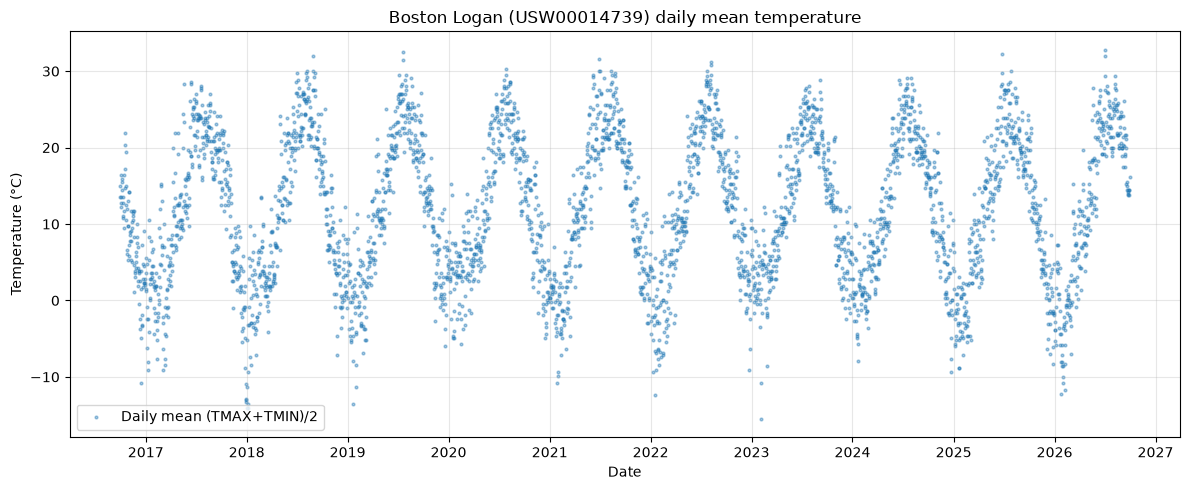

In [29]:
import matplotlib.pyplot as plt
import pandas as pd

CSV = "boston_logan_tmean_last10y.csv"
df = pd.read_csv(CSV, parse_dates=["DATE"])

fig, ax = plt.subplots(figsize=(12, 5))
ax.scatter(df["DATE"], df["TMEAN_C"], s=4, alpha=0.4, label="Daily mean (TMAX+TMIN)/2")

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Boston Logan (USW00014739) daily mean temperature")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()

As we can see, our data seems to follow a pretty cyclical pattern. In fact, the pattern looks a lot like a periodic function (such as $sin$ or $cos$)!

Let's make the guess that we can model our data using the following function:

$ \hat{y} = A\cos(\omega x+ \phi) + D$

Where:
- $A$ is the amplitude of our cosine wave (how big it is from the center to the maximum).
- $\omega$ is the *frequency* of our cosine wave (how long it takes to get from one peak to the next)
- $\phi$ is the *phase* of our cosine wave (where in the cycle it starts)
- $D$ is the *offset* of our cosine wave (how high it is above 0).

We can model this by using [`np.cos(X)`](https://numpy.org/devdocs/reference/generated/numpy.cos.html). One thing to be careful about - the function assumes that `x` is in radians.

(If you're rusty on your trig, [here's a refresher.](https://math.libretexts.org/Bookshelves/Precalculus/Active_Prelude_to_Calculus_(Boelkins)/02%3A_Circular_Functions/2.04%3A_Sinusoidal_Functions))

In [30]:
import numpy as np
test_x = np.cos(0)

print(test_x)

print(np.cos(np.pi))

# Close enough to zero!
print(np.cos(np.pi/2))

1.0
-1.0
6.123233995736766e-17


Here's some code to get our data from date time format to more workable numbers in an $X$ and $Y$ numpy array.

In [31]:
# Change it so our X simply represents Day 0 (Start), Day 1, Day 2.... Day 3651 (Last day in the Data)
X = (df["DATE"] - df["DATE"].min()).dt.days.to_numpy()
print("Day Number: ", X)

Y = df["TMEAN_C"].to_numpy()
print("Temp in C: ", Y)

Day Number:  [   0    1    2 ... 3649 3650 3651]
Temp in C:  [15.   13.6  12.8  ... 14.45 13.85 16.1 ]


#### **Exercise 2.2: SSE for Cosine**


Fill out the function *sum_squared_error_cos* which takes in a list of parameters $[A, \omega, \phi, D]$, and then calculates the sum of squared error on the function $\hat{Y} = f(X) =  A\cos(\omega X+ \phi) + D$ on our data $(X, Y)$. 

As a reminder, the SSE is:

$SSE = \sum_{i=0}^{n}(\hat{y_i}-y_i)^2$

In [39]:
def sum_squared_error_cos(params):
    sse = 0

    amp = params[0]
    frequency = params[1]
    phase = params[2]
    offset = params[3]
    predictions = amp * np.cos(frequency * X + phase) + offset
    sse = np.sum((predictions - Y) ** 2)
    return sse
    

In [40]:
grader.check("q_sse_cosine")

q_sse_cosine results: All test cases passed!

#### **Exercise 2.3: Minimizing SSE**

Now, let's actually try and minimize the SSE!

Before we do anything, we should make initial guesses of our parameters.

- Eyeballing the data from the plot, it looks like the center is at around 10, so we'll go with $D=10$
- Using this, also eyeballing the plot, it looks like the distance from the center (10) to the maximum (30) is around 20, so let's say $A = 20$.
- We know that our frequency should be close (if not exactly) to the time it takes for one revolution around the sun - 365.25 days. However we have to be careful about units, as `np.cos(x)` takes in *radians*. So we have to convert our period into radians. So $\omega = 2\pi/365.25$
- Finally, it looks like we're starting pretty close to the beginning of a cycle, so let's just say $\phi=0$

Note, you may get a warning that says something like `Desired error not necessarily achieved due to precision loss.` This is fine, you can safely ignore it.

In [34]:
import numpy as np
# You'll change these later - the originals in comments so you remember
initial_amp = 10 # 10
initial_frequency = 2 * np.pi / (365.25) # 2 * np.pi / (365.25)
initial_phase = 0 # 0
initial_offset = 10 # 10

initial_guess = [
    initial_amp,
    initial_frequency,
    initial_phase,
    initial_offset
]

Fill in the code below to store your results of your minimization in `res`.

In [41]:
from scipy.optimize import minimize

res = minimize(sum_squared_error_cos, initial_guess)

pred_amp = res["x"][0]
pred_omega = res["x"][1]
pred_phi = res["x"][2]
pred_offset = res["x"][3]
pred_values = pred_amp*np.cos(pred_omega*X + pred_phi) + pred_offset

In [42]:
grader.check("q_minimize_sse")

q_minimize_sse results: All test cases passed!

And then let's plot the result.

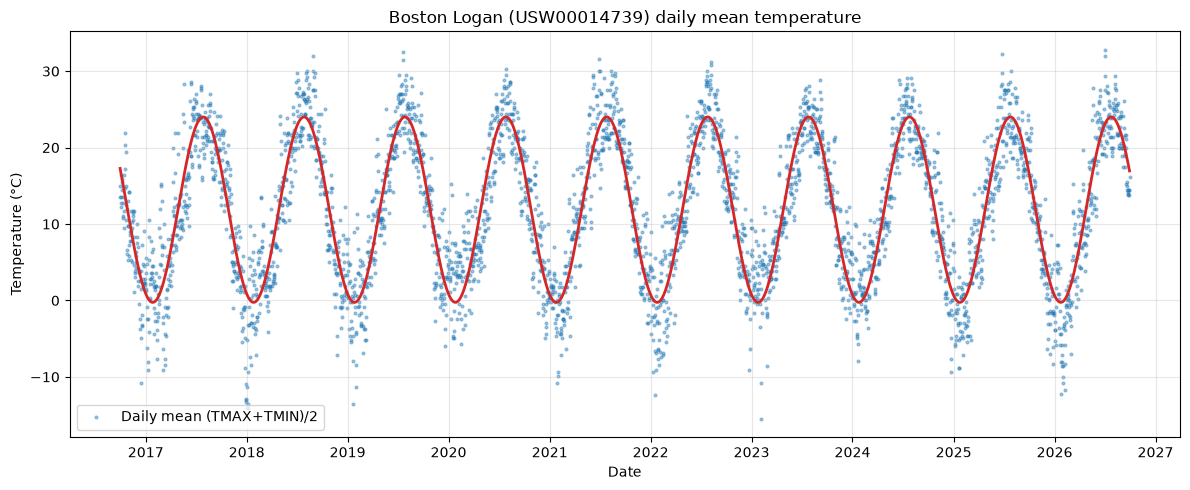

In [43]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(df["DATE"], pred_values, color="C3", lw=2)

ax.scatter(df["DATE"], df["TMEAN_C"], s=4, alpha=0.4, label="Daily mean (TMAX+TMIN)/2")

ax.set_xlabel("Date")
ax.set_ylabel("Temperature (°C)")
ax.set_title("Boston Logan (USW00014739) daily mean temperature")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
fig.tight_layout()
plt.show()


Looks good! It seems like our model fits the data well. We can now also make predictions using our model.


In [ ]:
# Get the day roughly two weeks from now
# Last day in the list + 14 days
two_weeks_from_now = X[-1]+14

predict_value = pred_amp*np.cos(pred_omega*two_weeks_from_now + pred_phi) + pred_offset

# We see that it's going to be 14 degrees C. It's gonna get colder!
print(predict_value)

However - you noticed we were pretty specific in our initial guesses. Did we just get lucky? Is it always that easy?

#### **Exercise 2.4 (Written): Sensitivity to Initial Guesses (5 pts)**

One at a time, for each parameter $[A, \omega, \phi, D]$:

- Try a few different initial guesses by nudging each of them up and down. Try at least 4 new initial parameters per variable (keeping others constant). Before you actually run the solver again - predict what will happen. Which variable's initial guess do you think would influence the final result the most? After running the solver multiple times, what do you notice? Did it line up with your predictions?


<!-- BEGIN QUESTION -->
- I expect the initial frequency to influence the final result the most. If the cycle length is wrong, the predicted summer and winter peaks will become increasingly misaligned with the data. I expect changes to the initial amplitude and offset to matter less because they mainly stretch the curve or move it vertically. Phase might also matter because it determines where the peaks start.

- The following table tries four new starting values for each parameter while leaving the other three at [10, 2π/365.25, 0, 10]. Smaller final SSE means a closer fit. “success” reports the solver's convergence flag; a precision-loss warning alone does not establish that the fit is bad.

- All four amplitude trials and all four offset trials reached SSE approximately 58,369, matching the baseline. All four frequency trials produced much worse SSE (approximately 313,527–326,961). Phase mattered too: starting at π/2 gave the good fit, but -π, -π/2, and π gave SSE around 326,906–326,951. In these trials, changing the frequency was consistently harmful, and three of four phase changes also spoiled the fit. This is joint optimization: even when only the initial phase changes, the solver can move the frequency during fitting.

- A small frequency error accumulates over thousands of days, moving later peaks out of alignment. Compare predictions or SSE rather than parameter values alone: changing the sign of amplitude and shifting phase by π gives the same curve, and adding 2π to phase leaves predictions unchanged. All trials reported a false convergence flag; the final SSE and fitted curve still distinguish the good fits from poor ones, but these runs do not certify a global optimum.

- The results mostly supported this prediction. All four new frequency guesses produced much higher final SSE values, around 313,527–326,961, compared with about 58,369 for the original fit. Changing the initial amplitude or offset led to approximately the same SSE as the original fit. However, phase mattered more than I expected: three of the four new phase guesses produced poor fits, while π/2 produced a good fit. This suggests that both frequency and phase starting values can affect whether the solver finds a good solution.


<!-- END QUESTION -->

#### **Exercise 2.5 (Written): Amplitude Sweep (5 pts)**


Let's try and formalize what you were playing with just now. Set back all of the initial guesses to their original value (in comments), such that the solver gives the original reasonable result that fits the data well.

In [44]:
pred_amp = res["x"][0]
pred_omega = res["x"][1]
pred_phi = res["x"][2]
pred_offset = res["x"][3]

To make that precise, we'll sweep one parameter at a time: hold the other three fixed at their fitted values, slide the target parameter through a range, and record how the final SSE changes. We'll do the first one, $A$, together.

In [45]:
# np.linspace chops up the space between [start, end] into 50 equal slices
# This is good for sweeping through a range of parameters
# E.g. evenly spacing out the interval [0, 10]
np.linspace(0,10)

array([ 0.        ,  0.20408163,  0.40816327,  0.6122449 ,  0.81632653,
        1.02040816,  1.2244898 ,  1.42857143,  1.63265306,  1.83673469,
        2.04081633,  2.24489796,  2.44897959,  2.65306122,  2.85714286,
        3.06122449,  3.26530612,  3.46938776,  3.67346939,  3.87755102,
        4.08163265,  4.28571429,  4.48979592,  4.69387755,  4.89795918,
        5.10204082,  5.30612245,  5.51020408,  5.71428571,  5.91836735,
        6.12244898,  6.32653061,  6.53061224,  6.73469388,  6.93877551,
        7.14285714,  7.34693878,  7.55102041,  7.75510204,  7.95918367,
        8.16326531,  8.36734694,  8.57142857,  8.7755102 ,  8.97959184,
        9.18367347,  9.3877551 ,  9.59183673,  9.79591837, 10.        ])

Text(0, 0.5, 'SSE')

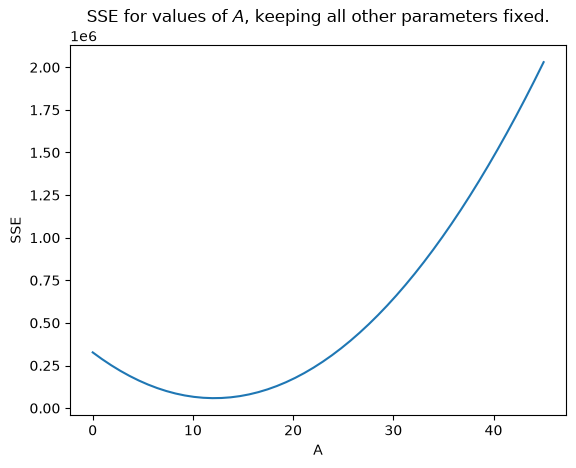

In [46]:
# Let's try amplitudes between 0 and 45
sweep_amp= np.linspace(0, 45)
sse_sweep_a = [sum_squared_error_cos([a, pred_omega, pred_phi, pred_offset]) for a in sweep_amp]
plt.plot(sweep_amp, sse_sweep_a)
plt.title("SSE for values of $A$, keeping all other parameters fixed.")
plt.xlabel("A")
plt.ylabel("SSE")

Notice how as we swept through $A$, there seems to be only one minimum at around 12. In fact, this minimum is exactly the minimum that our solver found (`pred_amp`). We can see that as we change $A$ the change in SSE is quite smooth. Answer the following question.

- For a simple gradient descent algorithm, would it be easy or difficult to find a good $A$ that corresponds to a good minimum of the $SSE$ (given we hold all other parameters constant)? Why?

<!-- BEGIN QUESTION -->

With frequency, phase, and offset fixed, finding the best amplitude should be easy for gradient descent with a suitable step size. Each prediction is linear in A, so the SSE is a convex quadratic in A: a smooth bowl with a single minimum for this data. There are no competing local minima to trap the algorithm. An excessively large step size could still make gradient descent overshoot.

<!-- END QUESTION -->

#### **Exercise 2.6 (Written): Sweeping the Other Parameters (20 pts)**

Create similar plots like we did for $A$ for $\omega, \phi$, and $D$. We've given you some candidate ranges to sweep through that you should use. Remember, for all other variables that you're not sweeping through, you should use the good predictions (`pred_`) 

- First, before writing any code: predict what the curve will look like for $\omega, \phi$, and $D$ as you sweep through each parameter and keep the others constant.

Then, write your code to do these plots and answer the following questions.

- For a simple gradient descent algorithm, would it be easy or difficult to find a good $\omega$ that corresponds to a good minimum of the $SSE$ (given we hold all other parameters constant)? Why?
- For a simple gradient descent algorithm, would it be easy or difficult to find a good $\phi$ that corresponds to a good minimum of the $SSE$ (given we hold all other parameters constant)? Why?
- For a simple gradient descent algorithm, would it be easy or difficult to find a good $D$ that corresponds to a good minimum of the $SSE$ (given we hold all other parameters constant)? Why?
- There's a general rule of thumb in curve fitting for sinusoidal data that you should always try and get a good estimate for the frequency over everything else to ensure a good curve fit. After doing this exercise, explain the reasoning behind this. Frame your answer in the language of gradient descent and local/global minima.

<!-- BEGIN QUESTION -->

- My prediction for changing ω is that the SSE curve will have several peaks and dips, with a deeper minimum near the frequency that best matches the yearly temperature cycle. For φ, I predict a roughly sinusoidal SSE curve that repeats every 2π, because shifting the phase by a full cycle gives the same predictions. For D, I predict a U-shaped curve. As the offset approaches the best value, the SSE will decrease. After passing that value, the SSE will increase because the predicted temperatures become too high.
  
- Finding the best value can be difficult. The curve has multiple dips because different frequencies partially line up with different portions of the data. Gradient descent follows the local slope and can stop at a worse local minimum instead of reaching the best valley near the annual frequency.
  
- The curve repeats every 2π. For this data, the displayed sweep has repeated valleys with the same best SSE. A reasonable step size will usually lead to a good valley; the repeated equivalent minima are less problematic than the unequal minima in the frequency sweep. Starting exactly at a stationary maximum could stall a pure gradient method. The phase curve need not be an exact sinusoid for an arbitrary finite dataset.
  
- The curve is a convex quadratic with one minimum. Gradient descent should find it easily with a suitable step size because there are no competing local minima.

- A frequency error changes phase by an amount proportional to elapsed time, so it can shift peaks substantially over a long dataset. This produces multiple basins in the loss. A starting frequency near the true seasonal frequency helps gradient descent enter the basin of the desired minimum. A single sweep fixes the other parameters, so it illustrates the problem without proving the full four-parameter objective has a unique global minimum.

<!-- END QUESTION -->



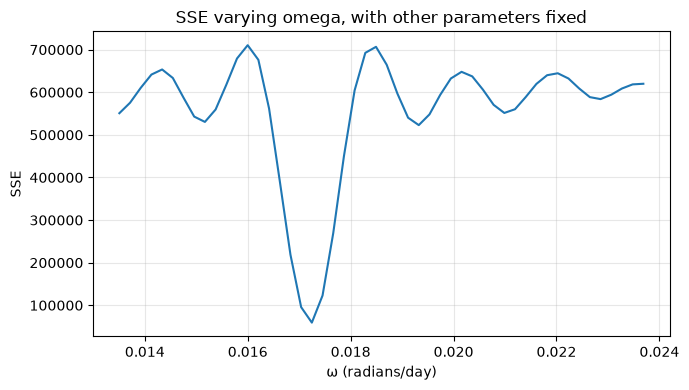

In [47]:
# Let's say our initial guess was somewhere between 100 days of the true value (365.25)
sweep_omega = np.linspace(2*np.pi/(365.25-100), 2*np.pi/(365.25+100))
sse_sweep_omega = [sum_squared_error_cos([pred_amp, value, pred_phi, pred_offset]) for value in sweep_omega]
plt.figure(figsize=(7, 4))
plt.plot(sweep_omega, sse_sweep_omega)
plt.xlabel("ω (radians/day)")
plt.ylabel("SSE")
plt.title("SSE varying omega, with other parameters fixed")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

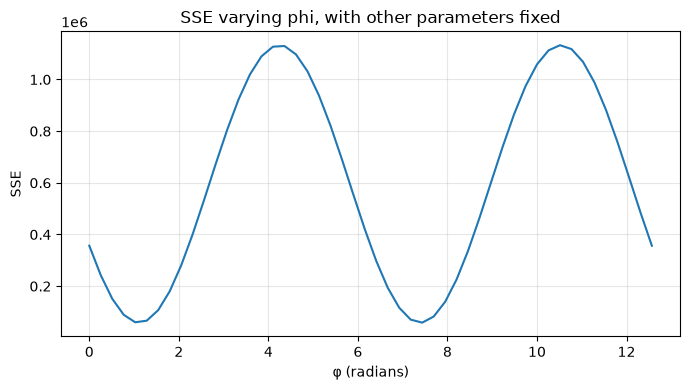

In [49]:
# Sweep through two cycles of the wave, just to get the full picture
sweep_phi= np.linspace(0, 4*np.pi)
sse_sweep_phi = [sum_squared_error_cos([pred_amp, pred_omega, value, pred_offset]) for value in sweep_phi]
plt.figure(figsize=(7, 4))
plt.plot(sweep_phi, sse_sweep_phi)
plt.xlabel("φ (radians)")
plt.ylabel("SSE")
plt.title("SSE varying phi, with other parameters fixed")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

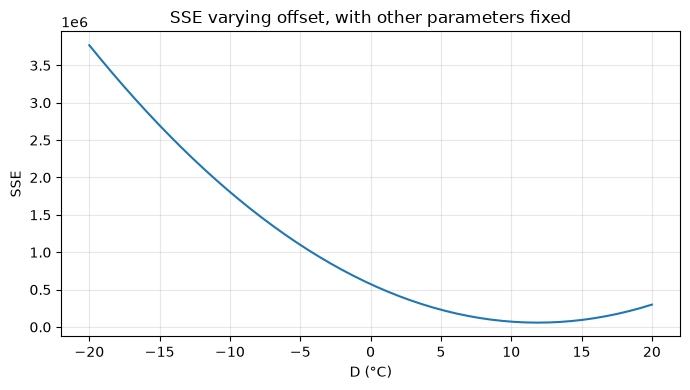

In [48]:
# Sweep through possible offsets
sweep_offset= np.linspace(-20, 20)
sse_sweep_offset = [sum_squared_error_cos([pred_amp, pred_omega, pred_phi, value]) for value in sweep_offset]
plt.figure(figsize=(7, 4))
plt.plot(sweep_offset, sse_sweep_offset)
plt.xlabel("D (°C)")
plt.ylabel("SSE")
plt.title("SSE varying offset, with other parameters fixed")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## **Collaboration Statement**

You are required to complete the following collaboration statement.


<!-- BEGIN QUESTION -->

- If you completed the lab in a group - list all your group members here, including yourself. **If you worked individually, you must state *"I worked by myself."***
    - I worked by myself/
- You must list the names of any others you got help from when completing this assignment (including TAs), and in what way you worked with them (discussed ideas, debugged math). **If you did not collaborate at all, you must state *"I did not collaborate with anyone else."***
    - I did not collaborate with anyone else.
- If you found any resources online helpful, you must link them and describe how you found them helpful (or not helpful). **If you did not use any resources online, you must state *"I did not use any resources online."***
    -I used Google to search up scify and various methods and functions and how they are used.
- If you used any AI assistive technologies, you must describe how you used them and how you found them helpful (or not helpful). **If you did not use any AI assistive technologies, you must state *"I did not use any AI assistive technologies."***
    - I did not use any AI assistive technologies.
- If you have any questions or comments about the material, or there was a topic or question you are confused on -- please make a note of it here! **If you do not have any questions or comments, you must state *"I do not have any questions or comments about the assignment."***
    - I do not have any questions or comments about the assignment.
- Estimate how long this assignment took you in hours. **You must give an estimate**.
    - This assignment took me about 3 hours to complete.


<!-- END QUESTION -->



## Submission

Make sure you have run all cells in your notebook in order before running the cell below, so that all images/graphs appear in the output. The cell below will generate a zip file for you to submit. **Please save before exporting!**

Run every cell from top to bottom and SAVE before exporting. Then submit
the generated .zip to the autograder assignment on Gradescope.


In [51]:
# Save your notebook first, then run this cell to export your submission.
grader.export(pdf=False, run_tests=True)

Running your submission against local test cases...


Your submission received the following results when run against available test cases:

    q_lp_flow results: All test cases passed!

    q_sse_cosine results: All test cases passed!

    q_minimize_sse results: All test cases passed!
